# Capítulo 6: Algoritmos 3 – Resolución de problemas con algoritmos

# Unidad 30: Enfoque Greedy (algoritmos codiciosos)

## 1. Definición y principio

El enfoque **Greedy (codicioso, voraz)** es una **tecnica de diseño de algoritmos** que llega a una solucion seleccionando la "mejor" eleccion del momento de una secuencia de elecciones segun criterios predefinidos.

> Busca una solución óptima tomando, **en cada paso, la mejor decisión local posible**, sin reconsiderar las elecciones pasadas.

Es una estrategia directa y eficiente para problemas en los que la suma de las mejores decisiones locales conduce a la **solución óptima global**.

> Analogía: al armar una maleta con poco espacio, siempre metes primero lo más útil que todavía quepa.



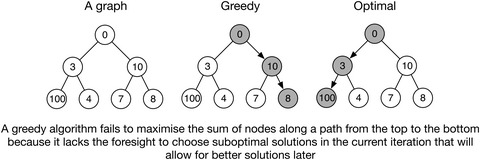

###**Que es un algoritmo codicioso**

Un algoritmo codicioso se refiere a cualquier algoritmo empleado para resolver un problema de optimización donde el algoritmo procede haciendo una elección localmente óptima (es decir, una elección codiciosa) con la esperanza de que resulte en una solución globalmente óptima.

**Características del algoritmo voraz**

* Los algoritmos codiciosos toman la mejor decisión en cada paso sin reconsiderar.
* Las decisiones tomadas son definitivas y no se pueden cambiar.
* Es posible que no siempre encuentren la mejor solución y en ocasiones puedan obtener resultados subóptimos.
* A pesar de esto, son rápidos en comparación con otros métodos como la programación dinámica.
* Los algoritmos codiciosos son intuitivos, pero es difícil demostrar su corrección matemáticamente.
* En algunos casos, pueden proporcionar soluciones casi óptimas cuando una solución exacta no es práctica.

## 2. Las 3 fases del diseño Greedy

| Fase | Pregunta que responde |
|---|---|
| **Procedimiento de selección** (*selection procedure*) | ¿Cuál es la mejor opción candidata ahora mismo? |
| **Comprobación de viabilidad** (*feasibility check*) | ¿La opción elegida cumple las restricciones del problema? |
| **Comprobación de la solución** (*solution check*) | ¿El conjunto actual ya resuelve el problema por completo? |

Plantilla general:

```python
def greedy(candidatos):
    solucion = []
    while candidatos and not es_solucion(solucion):      # 3. comprobación de la solución
        candidato = seleccionar(candidatos)              # 1. selección
        candidatos.remove(candidato)
        if es_viable(solucion, candidato):               # 2. viabilidad
            solucion.append(candidato)
    return solucion
```

> Esta plantilla es solo un esquema: `seleccionar`, `es_viable` y `es_solucion` cambian según el problema. Veamos dos problemas clásicos.



---



## 3. Problema del cambio de monedas (*Coin Change Problem*)

**Enunciado:** devolver el cambio exacto usando la **menor cantidad de monedas**.

**Estrategia greedy:** elegir siempre la moneda de **mayor denominación** que no supere la deuda restante.

| Fase | En este problema |
|---|---|
| Selección | La moneda más grande que quede disponible |
| Viabilidad | La moneda no puede superar lo que falta por devolver |
| Solución | Lo que falta por devolver es 0 |



---



**Propiedad de elección codiciosa**

Un problema tiene esta propiedad cuando la mejor solución global se puede lograr tomando siempre la mejor opción en cada paso (la elección local más conveniente).

Es decir: en cada paso eliges lo mejor sin preocuparte por lo que vendrá después.

Ejemplo: para dar cambio de 76 con monedas {50, 20, 5, 1}, eliges primero la moneda más grande que no se pase:

1. 76 → tomas 50 → queda 26

2. 26 → tomas 20 → queda 6

3. 6 → tomas 5 → queda 1

4. 1 → tomas 1 → queda 0

**Solución = {50, 20, 5, 1}, y resulta que es la mínima cantidad de monedas.**

In [1]:
def cambio_monedas(monto, monedas):
    """Devuelve la lista de monedas del cambio (estrategia greedy)."""
    monedas = sorted(monedas, reverse=True)   # de mayor a menor
    restante = monto
    cambio = []
    for moneda in monedas:
        # viabilidad: la moneda no debe superar lo que falta
        while moneda <= restante:
            cambio.append(moneda)
            restante -= moneda
    if restante != 0:
        return None                            # no se pudo dar el cambio exacto
    return cambio


# Monedas en centavos: 1, 5, 10, 25, 50, 100
monedas = [1, 5, 10, 25, 50, 100]
print(cambio_monedas(289, monedas))
print(cambio_monedas(63, monedas))

[100, 100, 50, 25, 10, 1, 1, 1, 1]
[50, 10, 1, 1, 1]


### Seguimiento paso a paso

In [2]:
def cambio_monedas_traza(monto, monedas):
    restante = monto
    for moneda in sorted(monedas, reverse=True):
        while moneda <= restante:
            restante -= moneda
            print(f"Entrego {moneda:>3} -> falta {restante}")
    print("Listo." if restante == 0 else "No se pudo completar el cambio.")

cambio_monedas_traza(63, [1, 5, 10, 25, 50, 100])

Entrego  50 -> falta 13
Entrego  10 -> falta 3
Entrego   1 -> falta 2
Entrego   1 -> falta 1
Entrego   1 -> falta 0
Listo.




---



###**Propiedad de subestructura óptima**

Un problema tiene esta propiedad cuando la solución óptima total se puede construir a partir de las soluciones óptimas de los subproblemas.

**Siguiendo el ejemplo:**

1. Elección codiciosa: primero tomo 50.

2. Subproblema: resolver el cambio de 26.

3. Para 26, el algoritmo da {20, 5, 1}.

**Combino: {50} ∪ {20, 5, 1} = {50, 20, 5, 1}.**

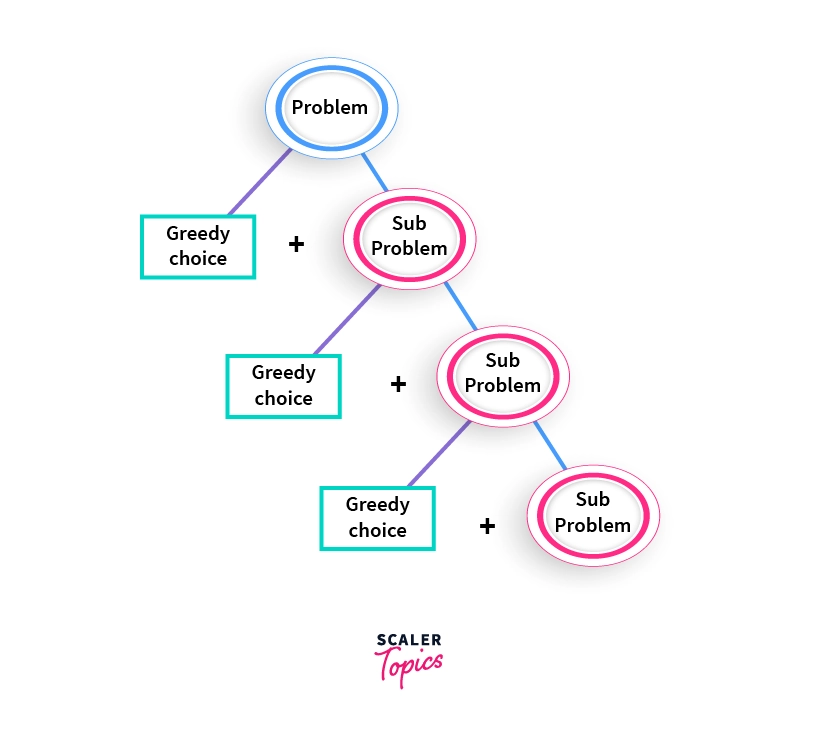

### ¿Greedy siempre da el mejor resultado?

**No siempre.** Con el sistema de monedas usual funciona, pero con otras denominaciones la decisión local puede **no** ser la óptima global.

In [3]:
# Con monedas {1, 3, 4} y monto 6:
print("Greedy:", cambio_monedas(6, [1, 3, 4]))   # [4, 1, 1] -> 3 monedas
print("Óptimo: [3, 3] -> 2 monedas")

Greedy: [4, 1, 1]
Óptimo: [3, 3] -> 2 monedas


> Conclusión: antes de usar Greedy hay que verificar que el problema admita esta estrategia. Si no, se necesitan otras técnicas.

## 4. Problema de selección de actividades (*Activity Selection Problem*)

**Enunciado:** se tienen solicitudes de reuniones para **una sola sala**, cada una con hora de inicio y de fin. ¿Cuál es el **número máximo de actividades no solapadas** que se pueden programar?

**Estrategia greedy:** ordenar las actividades por **hora de finalización** y elegir siempre la que termina primero y no se solapa con la última elegida.

| Fase | En este problema |
|---|---|
| Selección | La actividad que termina más temprano |
| Viabilidad | Su inicio es mayor o igual al fin de la última actividad elegida |
| Solución | Ya no quedan actividades por revisar |

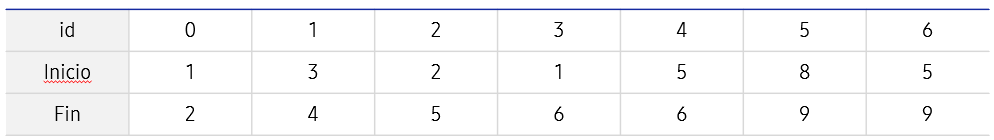



---



**Pregunta: ¿cuál es el máximo número de reuniones que se pueden atender sin que se solapen?**

**La estrategia es:**

1. Ordenar las reuniones por su hora de finalización (menor → mayor).

2. Seleccionar la primera que termina más temprano.

3. De ahí en adelante, elegir la siguiente reunión cuya hora de inicio sea ≥ hora de fin de la última seleccionada.

4. Repetir hasta agotar todas las solicitudes.



---



**Selección Greedy**

* Escogemos la primera (id=0, 1→2).

* Siguiente reunión que empieza después o igual a 2 → (id=1, 3→4).

* Siguiente reunión que empieza después o igual a 4 → (id=4, 5→6).

* Siguiente reunión que empieza después o igual a 6 → (id=5, 8→9).

In [4]:
def activity_selection(start, end):
    # start: lista con horas de inicio
    # end: lista con horas de fin
    n = len(start)
    activities = list(zip(range(n), start, end))  # (id, inicio, fin)

    # Paso 1: ordenar por hora de fin
    activities.sort(key=lambda x: x[2])

    selected = []  # aquí guardaremos las reuniones seleccionadas
    last_end = 0   # lleva el final de la última reunión aceptada

    # Paso 2: aplicar selección codiciosa
    for act in activities:
        act_id, s, f = act
        if s >= last_end:  # si no hay solapamiento
            selected.append(act_id)
            last_end = f  # actualizar la hora de fin
    return selected

# Datos del ejemplo
start = [1, 3, 2, 1, 5, 8, 5]
end   = [2, 4, 5, 6, 6, 9, 9]

resultado = activity_selection(start, end)
print("Reuniones seleccionadas:", resultado)

Reuniones seleccionadas: [0, 1, 4, 5]




---



###**Otra forma de realizarlo:**

In [5]:
def seleccion_actividades(actividades):
    """actividades: lista de tuplas (nombre, inicio, fin)."""
    # 1. Ordenar por hora de finalización
    ordenadas = sorted(actividades, key=lambda a: a[2])

    elegidas = []
    fin_ultima = 0
    for nombre, inicio, fin in ordenadas:
        if inicio >= fin_ultima:               # 2. viabilidad: no se solapa
            elegidas.append((nombre, inicio, fin))
            fin_ultima = fin
    return elegidas


reuniones = [
    ("A", 1, 4),
    ("B", 3, 5),
    ("C", 0, 6),
    ("D", 5, 7),
    ("E", 3, 9),
    ("F", 5, 9),
    ("G", 6, 10),
    ("H", 8, 11),
    ("I", 8, 12),
    ("J", 2, 14),
    ("K", 12, 16),
]

resultado = seleccion_actividades(reuniones)
print("Máximo de actividades:", len(resultado))
for nombre, inicio, fin in resultado:
    print(f"  {nombre}: {inicio} -> {fin}")

Máximo de actividades: 4
  A: 1 -> 4
  D: 5 -> 7
  H: 8 -> 11
  K: 12 -> 16


### Comparación: ¿y si ordenamos por hora de inicio?
Para ver por qué importa el criterio de selección, probemos otro criterio.

In [6]:
def seleccion_por_inicio(actividades):
    ordenadas = sorted(actividades, key=lambda a: a[1])   # por inicio (criterio malo)
    elegidas, fin_ultima = [], 0
    for nombre, inicio, fin in ordenadas:
        if inicio >= fin_ultima:
            elegidas.append((nombre, inicio, fin))
            fin_ultima = fin
    return elegidas

print("Ordenando por fin   :", len(seleccion_actividades(reuniones)), "actividades")
print("Ordenando por inicio:", len(seleccion_por_inicio(reuniones)), "actividades")

Ordenando por fin   : 4 actividades
Ordenando por inicio: 3 actividades




---



### Ejercicios propuestos
1. Calcula el cambio de `$0.87` con monedas de `1, 5, 10, 25` centavos y muestra cuántas monedas de cada tipo se usan.
2. Encuentra otro conjunto de monedas y un monto para el que Greedy **no** dé la solución óptima.
3. Modifica `seleccion_actividades` para que, además, devuelva el tiempo total ocupado de la sala.

---
# Unidad 31: Divide y Vencerás (*Divide and Conquer*)

Es un paradigma de diseño **recursivo** que descompone un problema en subproblemas más simples.

## 1. Las 3 etapas del paradigma

| Etapa | Qué hace |
|---|---|
| **Dividir** (*divide*) | Fragmenta la instancia original en dos o más subinstancias de menor tamaño |
| **Conquistar** (*conquer*) | Resuelve recursivamente cada subinstancia |
| **Combinar** (*combine*) | Integra las soluciones de las subinstancias para construir la respuesta al problema original |

Esquema general:

In [7]:
def divide_y_venceras(problema):
    if es_caso_base(problema):
        return resolver_directamente(problema)

    partes = dividir(problema)                              # Dividir
    soluciones = [divide_y_venceras(p) for p in partes]     # Conquistar
    return combinar(soluciones)                             # Combinar

## 2. Revisión de algoritmos Divide y Vencerás

Ya conocemos tres algoritmos de este paradigma. Veamos cómo cada uno aplica las tres etapas de forma distinta.

### 2.1 Búsqueda binaria

- **Divide:** el espacio de búsqueda a la mitad.
- **Conquista:** **solo una** de las dos partes (la otra se descarta).
- **Combina:** no hace falta combinar nada.

Requiere una lista **ordenada**.

In [8]:
def busqueda_binaria(S, objetivo, low=0, high=None):
    if high is None:
        high = len(S) - 1
    if low > high:
        return -1                                  # caso base: no está
    mid = (low + high) // 2
    if S[mid] == objetivo:
        return mid
    elif objetivo < S[mid]:
        return busqueda_binaria(S, objetivo, low, mid - 1)    # solo la mitad izquierda
    else:
        return busqueda_binaria(S, objetivo, mid + 1, high)   # solo la mitad derecha


L = [2, 5, 8, 12, 16, 23, 38, 56, 72, 91]
print(busqueda_binaria(L, 23))   # 5
print(busqueda_binaria(L, 10))   # -1

5
-1


### 2.2 Ordenamiento por Fusión (*Merge Sort*)

- **Divide:** la lista en **dos partes iguales**.
- **Conquista:** ordena **ambas** partes recursivamente.
- **Combina:** requiere una etapa **explícita** de combinación (*merge*).

In [9]:
def merge(L, R):
    resultado, i, j = [], 0, 0
    while i < len(L) and j < len(R):
        if L[i] <= R[j]:
            resultado.append(L[i]); i += 1
        else:
            resultado.append(R[j]); j += 1
    return resultado + L[i:] + R[j:]


def mergesort(S):
    if len(S) <= 1:
        return S
    mid = len(S) // 2
    return merge(mergesort(S[:mid]), mergesort(S[mid:]))   # Dividir, conquistar y combinar


print(mergesort([38, 27, 43, 3, 9, 82, 10]))

[3, 9, 10, 27, 38, 43, 82]


### 2.3 Ordenamiento Rápido (*Quick Sort*)

- **Divide:** según un **pivote**, en sublistas de tamaños **variables**.
- **Conquista:** ordena ambas sublistas recursivamente.
- **Combina:** **no requiere** combinar al final, porque el trabajo se hizo al particionar.

In [10]:
def quicksort(S):
    if len(S) <= 1:
        return S
    pivote = S[len(S) // 2]
    menores = [x for x in S if x < pivote]
    iguales = [x for x in S if x == pivote]
    mayores = [x for x in S if x > pivote]
    return quicksort(menores) + iguales + quicksort(mayores)   # solo se concatena


print(quicksort([38, 27, 43, 3, 9, 82, 10]))

[3, 9, 10, 27, 38, 43, 82]


### Comparación de los tres

| Algoritmo | Cómo divide | ¿Resuelve ambas partes? | ¿Combina? |
|---|---|---|---|
| Búsqueda binaria | En dos mitades | No, solo una | No |
| Fusión (*Merge Sort*) | En dos partes iguales | Sí, ambas | Sí, con *merge* |
| Rápido (*Quick Sort*) | Según el pivote, tamaños variables | Sí, ambas | No |

### Ejercicios propuestos
1. Modifica `costo` para encontrar la **suma máxima** en lugar de la mínima.
2. Prueba `ruta_minima` con este triángulo y comprueba el resultado a mano: `[[1], [2, 3], [4, 5, 6], [7, 8, 9, 10]]`.
3. Escribe `busqueda_binaria` de forma **iterativa** (con un `while`) y compara las dos versiones.
4. Para cada algoritmo de la tabla comparativa, escribe con tus palabras qué hace cada etapa: dividir, conquistar y combinar.



---



##**Algoritmo de Dijkstra (camino más corto) - Grafos**

###**¿Qué es?**

Es un algoritmo para encontrar la distancia mínima desde un nodo origen hasta todos los demás nodos en un grafo con pesos positivos.



###**Cómo funciona**

1. Inicializa todas las distancias en ∞, excepto el nodo origen (0).

2. Escoge el nodo con la distancia más pequeña (Greedy).

3. Actualiza (relaja) las distancias de sus vecinos.

4. Marca el nodo como “visitado”.

5. Repite hasta procesar todos los nodos.

###**Estructura**

Entrada: un grafo con nodos, aristas y pesos.

Salida: lista/diccionario con la distancia mínima desde el origen a cada nodo.

###**Código en Python**

In [11]:
import heapq

def dijkstra(grafo, inicio):
    # Inicializamos distancias: todos en infinito excepto el nodo de inicio
    distancias = {nodo: float("inf") for nodo in grafo}
    distancias[inicio] = 0

    # Usamos una cola de prioridad (Greedy: siempre saca el nodo más cercano)
    cola = [(0, inicio)]

    while cola:
        distancia_actual, nodo_actual = heapq.heappop(cola)

        # Si ya tenemos una mejor distancia, lo ignoramos
        if distancia_actual > distancias[nodo_actual]:
            continue

        # Revisamos vecinos
        for vecino, peso in grafo[nodo_actual]:
            nueva_distancia = distancia_actual + peso
            if nueva_distancia < distancias[vecino]:  # Relajación
                distancias[vecino] = nueva_distancia
                heapq.heappush(cola, (nueva_distancia, vecino))

    return distancias

# Ejemplo de grafo representado con diccionario
grafo = {
    "A": [("B", 2), ("C", 5)],
    "B": [("A", 2), ("D", 3)],
    "C": [("A", 5), ("D", 2)],
    "D": [("B", 3), ("C", 2)]
}

print(dijkstra(grafo, "A"))

{'A': 0, 'B': 2, 'C': 5, 'D': 5}


###**Aplicación Greedy**

En cada iteración, Dijkstra elige codiciosamente el nodo con la menor distancia conocida hasta ahora. Esa elección local asegura el resultado global óptimo.



---



##**Algoritmo de Kruskal (árbol de expansión mínima - MST)**

###**¿Qué es?**

Es un algoritmo que construye un árbol de expansión mínima (MST): conecta todos los nodos de un grafo con el menor costo posible y sin ciclos.



###**Cómo funciona (pasos)**

1. Ordena todas las aristas por peso (menor → mayor).

2. Inicializa un conjunto para representar cada nodo (usando Union-Find).

3. Itera sobre las aristas:

    * Si conecta dos conjuntos diferentes, añádela al MST.

    * Si forma ciclo, se descarta.

    * Termina cuando todos los nodos están conectados.

###**Estructura**

* Entrada: conjunto de nodos y aristas con pesos.

* Salida: lista de aristas que forman el MST.

###**Codigo**

In [12]:
# Estructura de Union-Find (para manejar conjuntos)
class UnionFind:
    def __init__(self, n):
        self.padre = list(range(n))

    def find(self, x):
        if self.padre[x] != x:
            self.padre[x] = self.find(self.padre[x])
        return self.padre[x]

    def union(self, x, y):
        raizX, raizY = self.find(x), self.find(y)
        if raizX != raizY:
            self.padre[raizY] = raizX
            return True
        return False

def kruskal(nodos, aristas):
    # Ordenamos las aristas por peso (Greedy)
    aristas.sort(key=lambda x: x[2])

    uf = UnionFind(nodos)
    mst = []

    for u, v, peso in aristas:
        if uf.union(u, v):  # Si no hay ciclo, se agrega al MST
            mst.append((u, v, peso))

    return mst

# Ejemplo: grafo con 4 nodos (0,1,2,3)
aristas = [
    (0, 1, 1),
    (1, 2, 3),
    (2, 3, 2),
    (0, 2, 4)
]

print(kruskal(4, aristas))

[(0, 1, 1), (2, 3, 2), (1, 2, 3)]


###**Aplicación Greedy**

Kruskal es Greedy porque elige siempre la arista más barata disponible que no forme ciclo. Cada elección local contribuye al MST global óptimo.

---
# Resumen

| Enfoque | Idea principal | Ejemplos de la unidad |
|---|---|---|
| **Greedy** | Elegir en cada paso la mejor opción local, sin volver atrás | Cambio de monedas, selección de actividades |
| **Divide y Vencerás** | Dividir, resolver las partes recursivamente y combinar | Búsqueda binaria, *Merge Sort*, *Quick Sort*, ruta mínima del triángulo |

**Para recordar**

- Greedy: *selección → viabilidad → comprobación de la solución*.
- Divide y Vencerás: *dividir → conquistar → combinar*.
- Greedy es rápido y simple, pero **no siempre** garantiza el mejor resultado: hay que verificar que el problema lo permita.